In [1]:
# import packages
import pandas as pd
import numpy as np
import datetime as dt
import scipy.stats as sp
%load_ext google.cloud.bigquery
import pickle
from matplotlib import pyplot as plt
from datetime import datetime
# with open('design.pkl','rb') as f:
#     set_params = pickle.load(f)
# plt.rcParams.update(set_params)

from google.cloud import bigquery

In [14]:
# Modules
from modules.connector import MyBigQuery, MySQL
bq = MyBigQuery(
    credentials_file="./credentials/New AutoMotive Index-487e031dc242.json"
)

In [8]:
# Let's see who has more CO2 room to breathe

# How do we work out the cap on CO2 transfers, and who has maxed out their CO2 flex?



total_cars = 100
ice_cars = 90

emissions_reduction = 10

zev_credits = (emissions_reduction * ice_cars)/197

def zev_credits(total_cars, ice_cars, year, total_cars):
    co2_cap = {
        2024: [.78, .143],
        2025: [.72, .126],
        2026: [.67, .0825]
    }

    
    
    additional_zevm_credits = 

    return additional_zevm_credits

In [12]:
# Given ICE, total_sales and baseline, what's the max worthwhile emissions reductions?

def worthwhile_reductions(year, total_registrations, ices, baseline):
    co2_cap = {
            2024: [.78, .143],
            2025: [.72, .126],
            2026: [.67, .0825]
        }
    cap = co2_cap[year][0] * co2_cap[year][1] * total_registrations

    cap_co2_allowances = cap * 167

    min_co2 = cap_co2_allowances / ices


    return min_co2

In [13]:
# let's say a carmaker has a baseline of 160, 100 registrations, and 10 bevs

worthwhile_reductions(
    year = 2024,
    total_registrations = 100,
    ices = 90,
    baseline = 190
)

20.69686666666667

In [18]:
# import baselines
bl = pd.read_csv('Potential Flexibilities_ ZEV Mandate Model - Calcs - RE.csv')[['manufacturer', 'CO2 Target']]
# bl

In [23]:
cars = bq.from_bq_to_dataframe(
query = """
WITH targets_non_zev as(
  SELECT manufacturer, AVG(co2Emissions) as avgCO2_2021_inz
  FROM VES_dataset.parentZEVMandateM1
  WHERE typeApproval = 'M1'
  AND monthOfFirstRegistration > '2020-12-31'
  AND monthOfFirstRegistration < '2022-01-01'
  GROUP BY manufacturer
  
)

SELECT 
    VES.manufacturer,
    COUNT(*) as totalSales,
    COUNTIF(VES.co2Emissions > 0) as nonzevSales,
    COUNTIF(VES.co2Emissions = 0) as zevSales,
    SUM(VES.co2Emissions) as co2Activity,


FROM VES_dataset.parentZEVMandateM1 VES
LEFT JOIN targets_non_zev TNZ
ON VES.manufacturer = TNZ.manufacturer

WHERE VES.typeApproval = 'M1'
AND CAST(VES.monthOfFirstRegistration AS DATE) > '2023-12-31'
AND CAST(VES.monthOfFirstRegistration AS DATE) < DATE_TRUNC(CURRENT_DATE(), MONTH)
AND region IN ('GB')
AND CAST(VES.monthOfFirstRegistration AS DATE) <= '2024-11-01'

# Volume limit
#AND VES.manufacturer IN (
#    SELECT manufacturer
#    FROM VES_dataset.parentZEVMandateM1
#    WHERE typeApproval = 'M1'
#    AND CAST(monthOfFirstRegistration AS DATE) >= DATE_SUB(DATE_TRUNC(CURRENT_DATE(), MONTH), INTERVAL 1 YEAR)
#    AND CAST(monthOfFirstRegistration AS DATE) < DATE_TRUNC(CURRENT_DATE(), MONTH)
#    -- AND total > 2500
#    GROUP BY manufacturer
#    HAVING COUNT(*) > 2500
#)



GROUP BY VES.manufacturer, TNZ.avgCO2_2021_inz
ORDER BY VES.manufacturer ASC 

""")

In [26]:
cars = cars.merge(bl, how='left', on='manufacturer')

In [38]:
cars = cars.dropna()
cars = cars.query("nonzevSales > 0")

In [41]:
cars['max_co2_reduction'] = cars.apply(lambda row: worthwhile_reductions(
    year = 2024,
    total_registrations = row['totalSales'],
    ices = row['nonzevSales'],
    baseline = row['CO2 Target']
), axis=1)

cars['max_co2_reduction_2025'] = cars.apply(lambda row: worthwhile_reductions(
    year = 2025,
    total_registrations = row['totalSales'],
    ices = row['nonzevSales'],
    baseline = row['CO2 Target']
), axis=1)

cars['max_co2_reduction_2026'] = cars.apply(lambda row: worthwhile_reductions(
    year = 2026,
    total_registrations = row['totalSales'],
    ices = row['nonzevSales'],
    baseline = row['CO2 Target']
), axis=1)

In [105]:
cars['co2_reduction'] = cars['CO2 Target'] - (cars['co2Activity'] / cars['nonzevSales'])

In [106]:
cars

,manufacturer,totalSales,nonzevSales,zevSales,co2Activity,CO2 Target,max_co2_reduction,max_co2_reduction_2025,max_co2_reduction_2026,co2_curr,co2_reduction
0,ADAM OPEL GMBH,64513,52030,12483,6669139.0,128.0,23.096200,18.785075,11.445602,128.178724,-0.178724
1,ALFA ROMEO SPA,1280,1242,38,164110.0,190.0,19.197094,15.613774,9.513353,132.133655,57.866345
2,ASTON MARTIN LAGONDA LTD,498,498,0,146399.0,295.0,18.627180,15.150240,9.230925,293.973896,1.026104
3,AUDI AG,95783,78825,16958,10639998.0,144.0,22.634534,18.409584,11.216818,134.982531,9.017469
4,AUTOMOBILE DACIA SA,23384,23054,330,2955762.0,135.0,18.893814,15.367104,9.363058,128.210376,6.789624
5,AUTOMOBILES CITROEN,25854,22491,3363,2918707.0,126.0,21.412437,17.415602,10.611193,129.772220,-3.772220
6,AUTOMOBILES PEUGEOT,55336,43713,11623,5482420.0,127.0,23.580025,19.178589,11.685367,125.418525,1.581475
7,AUTOMOBILI LAMBORGHINI SPA,474,474,0,157628.0,347.0,18.627180,15.150240,9.230925,332.548523,14.451477
8,BAYERISCHE MOTOREN WERKE AG,122440,91967,30473,12234980.0,133.0,24.799242,20.170228,12.289565,133.036633,-0.036633
9,BENTLEY MOTORS LTD,476,476,0,114133.0,275.0,18.627180,15.150240,9.230925,239.775210,35.224790


In [185]:
## Graphing the current situation wrt to CO2 flexibilities

em = bq.from_bq_to_dataframe(
query = """
SELECT 
    VES.manufacturer,
    monthOfFirstRegistration,
    AVG(co2Emissions) as emissions
FROM VES_dataset.parentZEVMandateM1 VES
WHERE monthOfFirstRegistration > '2020-12-31'
AND monthOfFirstRegistration < '2024-11-01'
AND manufacturer IN ('NISSAN INTERNATIONAL SA', 'VOLKSWAGEN AG', 'TOYOTA MOTOR EUROPE NV SA', 'FORD-WERKE GMBH')
AND co2Emissions > 0
GROUP BY VES.manufacturer, monthOfFirstRegistration


""")

em['monthOfFirstRegistration'] = pd.to_datetime(em.monthOfFirstRegistration)

em

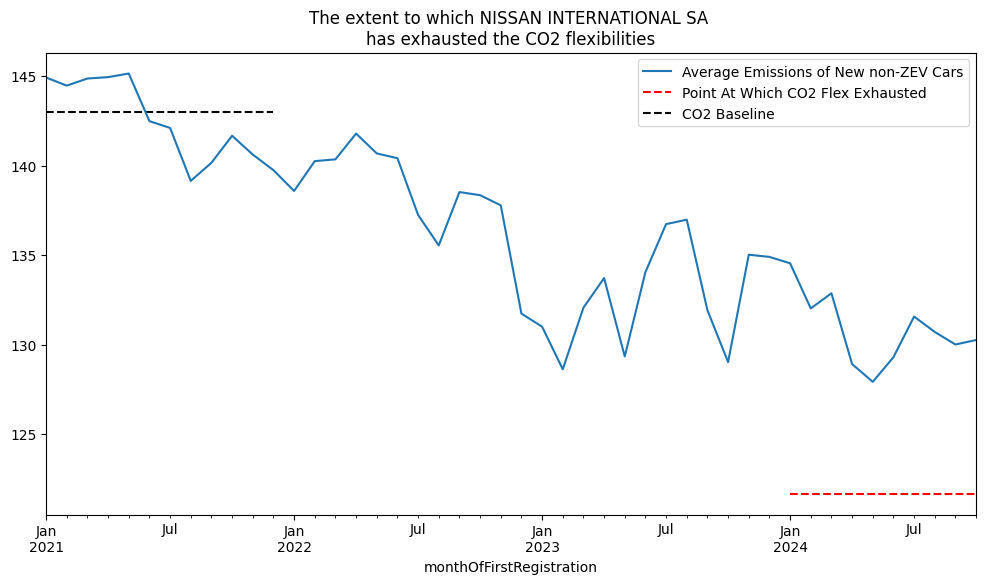

In [187]:
man = 'NISSAN INTERNATIONAL SA'

df = em[em.manufacturer == man].set_index('monthOfFirstRegistration').sort_index()


fig, ax = plt.subplots(figsize=(12, 6))

df.emissions.plot(ax=ax, label='Average Emissions of New non-ZEV Cars')

baseline = cars.set_index('manufacturer').loc[man, 'CO2 Target']

lim_2024 = baseline - cars.set_index('manufacturer').loc[man, 'max_co2_reduction']
start_date = pd.Timestamp("2024-01-01")
end_date = pd.Timestamp("2024-12-31")
ax.hlines(y=lim_2024, xmin=start_date, xmax=end_date, colors='red', linestyles='dashed', label='Point At Which CO2 Flex Exhausted')

# lim_2025 = baseline - cars.set_index('manufacturer').loc[man, 'max_co2_reduction_2025']
# start_date_2025 = pd.Timestamp("2025-01-01")
# end_date_2025 = pd.Timestamp("2025-12-31")
# ax.hlines(y=lim_2024, xmin=start_date_2025, xmax=end_date_2025, colors='red', linestyles='dashed', label='Point At Which CO2 Flex Exhausted')

# lim_2026 = baseline - cars.set_index('manufacturer').loc[man, 'max_co2_reduction_2026']
# start_date_2026 = pd.Timestamp("2026-01-01")
# end_date_2026 = pd.Timestamp("2026-12-31")
# ax.hlines(y=lim_2024, xmin=start_date_2026, xmax=end_date_2026, colors='red', linestyles='dashed', label='Point At Which CO2 Flex Exhausted')

baseline_start_date = pd.Timestamp("2021-01-01")
baseline_end_date = pd.Timestamp("2021-12-31")
ax.hlines(y=baseline, xmin=baseline_start_date, xmax=baseline_end_date, colors='black', linestyles='dashed', label='CO2 Baseline')

ax.set_title('The extent to which {m} \nhas exhausted the CO2 flexibilities'.format(m=man))

ax.legend()
# ax.set_xlim(pd.Timestamp('2021-01-01'), pd.Timestamp('2026-12-31'))
# ax.set_ylim(100, 150)


In [182]:
cars.set_index('manufacturer').loc[man, 'max_co2_reduction_2025']

16.846655899383475

In [183]:
cars.set_index('manufacturer').loc[man, 'max_co2_reduction']

20.712918860419236

In [184]:
em

,manufacturer,monthOfFirstRegistration,emissions
0,VOLKSWAGEN AG,2021-08-01 00:00:00+00:00,135.556689
1,TOYOTA MOTOR EUROPE NV SA,2021-02-01 00:00:00+00:00,117.406870
2,TOYOTA MOTOR EUROPE NV SA,2023-11-01 00:00:00+00:00,107.819269
3,VOLKSWAGEN AG,2023-09-01 00:00:00+00:00,130.310062
4,TOYOTA MOTOR EUROPE NV SA,2021-03-01 00:00:00+00:00,117.597467
...,...,...,...
133,TOYOTA MOTOR EUROPE NV SA,2023-12-01 00:00:00+00:00,109.359402
134,TOYOTA MOTOR EUROPE NV SA,2021-10-01 00:00:00+00:00,112.229312
135,VOLKSWAGEN AG,2024-06-01 00:00:00+00:00,131.828828
136,NISSAN INTERNATIONAL SA,2024-06-01 00:00:00+00:00,129.300729
